# COMP5313 — Project 2: Word Embedding for Sentiment Analysis
**Student:** Yishu Chen  
**Dataset:** Stanford IMDb (`stanfordnlp/imdb`), 25,000 train and 25,000 test  
**Comparison:** TF–IDF + Logistic Regression vs. GloVe (50-d average embeddings) + Logistic Regression

This notebook is an independent, reproducible implementation based on the assignment specifications. Run **Kernel → Restart & Run All** in order. Results and the final `ReadMe.pdf` are generated **only after successful execution**.

**Environment:** Python 3.10–3.12; install the listed requirements using `python -m pip install -r requirements.txt`. First execution needs internet to download the pretrained GloVe vectors (~66 MB). No GPU required.

## 1. Imports and reproducibility
Both models use the same fixed training/test partitions. All preprocessing and TF-IDF fitting use only the training data.

In [1]:
from pathlib import Path
import html
import json
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Working directory:", ROOT)
print("Python dependencies imported successfully.")

Working directory: /Users/xanor/Desktop/COMP5313_Project2_YishuChen 3
Python dependencies imported successfully.


## 2. Load and verify IMDb dataset
These Parquet files come from the supplied repository. The `label` column must be binary (0 = Negative, 1 = Positive).

In [2]:
train_path = DATA_DIR / "train-00000-of-00001.parquet"
test_path = DATA_DIR / "test-00000-of-00001.parquet"
for p in (train_path, test_path):
    if not p.is_file():
        raise FileNotFoundError(f"Missing dataset file: {p}. Keep the project data/ folder beside this notebook.")
train_df = pd.read_parquet(train_path)
test_df = pd.read_parquet(test_path)
required = {"text", "label"}
assert required.issubset(train_df.columns) and required.issubset(test_df.columns)
assert set(train_df["label"].dropna().unique()) == {0, 1}
assert set(test_df["label"].dropna().unique()) == {0, 1}
assert len(train_df) == 25_000 and len(test_df) == 25_000, "Unexpected split sizes"
assert not train_df[["text", "label"]].isna().any().any()
assert not test_df[["text", "label"]].isna().any().any()
print("Train:", train_df.shape, "Test:", test_df.shape)
print("Train label counts:", train_df["label"].value_counts().sort_index().to_dict())
print("Test label counts:", test_df["label"].value_counts().sort_index().to_dict())
print("Example review excerpt:", train_df["text"].iloc[0][:220].replace("\n", " "))

Train: (25000, 2) Test: (25000, 2)
Train label counts: {0: 12500, 1: 12500}
Test label counts: {0: 12500, 1: 12500}
Example review excerpt: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter th


## 3. Text normalization
Keep negation words such as "not" (important for sentiment). Apply the same cleaning to train/test and to new text at prediction time.

In [3]:
def clean_text(text: str) -> str:
    text = html.unescape(str(text)).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

x_train = train_df["text"].map(clean_text).tolist()
x_test = test_df["text"].map(clean_text).tolist()
y_train = train_df["label"].to_numpy(dtype=int)
y_test = test_df["label"].to_numpy(dtype=int)
print("Before:", train_df["text"].iloc[0][:160])
print("After: ", x_train[0][:160])

Before: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at firs
After:  i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it w


## 4. Model A: TF–IDF + Logistic Regression
Use 1–2-grams and remove excessively rare features. **Fit vectorizer on training reviews only** to avoid leakage.

In [4]:
t0 = time.perf_counter()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100_000, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(x_train)
X_test_tfidf = vectorizer.transform(x_test)
model_tfidf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="liblinear")
model_tfidf.fit(X_train_tfidf, y_train)
tfidf_fit_seconds = time.perf_counter() - t0
pred_tfidf = model_tfidf.predict(X_test_tfidf)
print("TF-IDF train matrix:", X_train_tfidf.shape)
print(f"TF-IDF fit time (vectorizer + classifier): {tfidf_fit_seconds:.2f}s")
print(f"TF-IDF test accuracy: {accuracy_score(y_test, pred_tfidf):.4%}")
print(classification_report(y_test, pred_tfidf, target_names=["Negative", "Positive"], digits=4))

TF-IDF train matrix: (25000, 100000)
TF-IDF fit time (vectorizer + classifier): 16.14s
TF-IDF test accuracy: 89.9280%
              precision    recall  f1-score   support

    Negative     0.9027    0.8950    0.8989     12500
    Positive     0.8959    0.9035    0.8997     12500

    accuracy                         0.8993     25000
   macro avg     0.8993    0.8993    0.8993     25000
weighted avg     0.8993    0.8993    0.8993     25000



## 5. Model B: pretrained GloVe + Logistic Regression
Download the `glove-wiki-gigaword-50` pretrained vectors via Gensim (first run only, internet required). Represent each review by the mean of its **in-vocabulary** token vectors. This is a static embedding baseline: word order and context are lost by averaging. The pretrained model was trained on external text, not on IMDb test labels.

If download is blocked, install/connect to the internet and rerun this cell. Do **not** replace missing embeddings with fabricated data.

In [5]:
import gensim.downloader as api

print("Loading pretrained glove-wiki-gigaword-50 vectors (first run downloads ~66 MB)...")
try:
    glove = api.load("glove-wiki-gigaword-50")
except Exception as exc:
    raise RuntimeError("GloVe download/load failed. Check internet access and gensim/scipy installation; rerun this cell.") from exc
EMBED_DIM = glove.vector_size
print("Pretrained embedding dimension:", EMBED_DIM)

def glove_review_vector(text: str) -> np.ndarray:
    tokens = text.split()
    vectors = [glove[w] for w in tokens if w in glove]
    return np.mean(vectors, axis=0) if vectors else np.zeros(EMBED_DIM, dtype=np.float32)

t0 = time.perf_counter()
X_train_glove = np.vstack([glove_review_vector(text) for text in x_train]).astype(np.float32)
X_test_glove = np.vstack([glove_review_vector(text) for text in x_test]).astype(np.float32)
model_glove = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver="liblinear")
model_glove.fit(X_train_glove, y_train)
glove_fit_seconds = time.perf_counter() - t0
pred_glove = model_glove.predict(X_test_glove)
print("GloVe train matrix:", X_train_glove.shape)
print(f"GloVe feature construction + classifier fit time (pretrained download excluded): {glove_fit_seconds:.2f}s")
print(f"GloVe test accuracy: {accuracy_score(y_test, pred_glove):.4%}")
print(classification_report(y_test, pred_glove, target_names=["Negative", "Positive"], digits=4))

Loading pretrained glove-wiki-gigaword-50 vectors (first run downloads ~66 MB)...
Pretrained embedding dimension: 50
GloVe train matrix: (25000, 50)
GloVe feature construction + classifier fit time (pretrained download excluded): 11.80s
GloVe test accuracy: 75.6440%
              precision    recall  f1-score   support

    Negative     0.7504    0.7685    0.7593     12500
    Positive     0.7628    0.7444    0.7535     12500

    accuracy                         0.7564     25000
   macro avg     0.7566    0.7564    0.7564     25000
weighted avg     0.7566    0.7564    0.7564     25000



## 6. Fair comparison and actual measured results
Use test-set metrics for each model. Both models share the exact IMDb test reviews. Training time is shown for context, not as a completely equivalent cost measure (pretraining/download is excluded for GloVe).

                           Model  Accuracy  Precision (weighted)  Recall (weighted)  F1 (weighted)  Fit/feature time (s)
    TF-IDF + Logistic Regression    0.8993                0.8993             0.8993         0.8993               16.1383
GloVe mean + Logistic Regression    0.7564                0.7566             0.7564         0.7564               11.7987


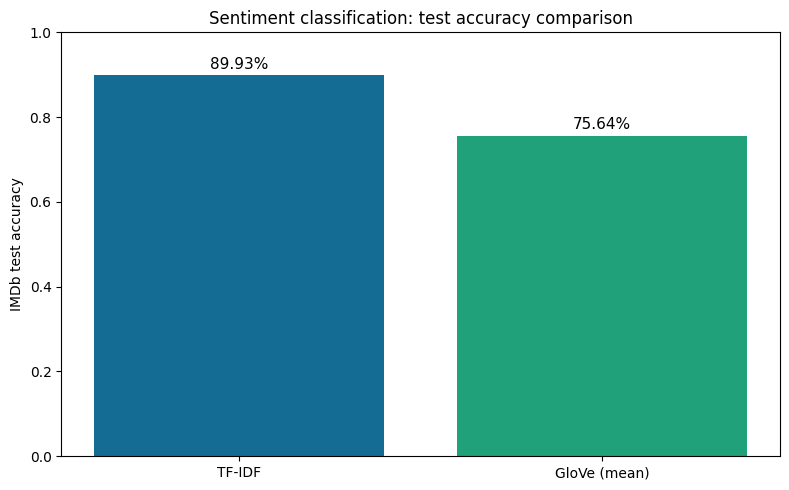

In [6]:
def evaluate(name, predicted, seconds):
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, predicted, average="weighted", zero_division=0)
    return {"Model": name, "Accuracy": float(accuracy_score(y_test, predicted)),
            "Precision (weighted)": float(precision), "Recall (weighted)": float(recall),
            "F1 (weighted)": float(f1), "Fit/feature time (s)": float(seconds)}

results = pd.DataFrame([
    evaluate("TF-IDF + Logistic Regression", pred_tfidf, tfidf_fit_seconds),
    evaluate("GloVe mean + Logistic Regression", pred_glove, glove_fit_seconds),
])
print(results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
results.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(results.to_dict(orient="records"), f, indent=2)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(["TF-IDF", "GloVe (mean)"], results["Accuracy"], color=["#146c94", "#21a179"])
ax.set_ylim(0, 1)
ax.set_ylabel("IMDb test accuracy")
ax.set_title("Sentiment classification: test accuracy comparison")
for b, v in zip(bars, results["Accuracy"]):
    ax.text(b.get_x() + b.get_width()/2, v + .015, f"{v:.2%}", ha="center", fontsize=11)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "accuracy_comparison.png", dpi=180)
plt.show()

## 7. Confusion matrices
Rows are true labels and columns are predicted labels. This shows false positives and false negatives as well as accuracy.

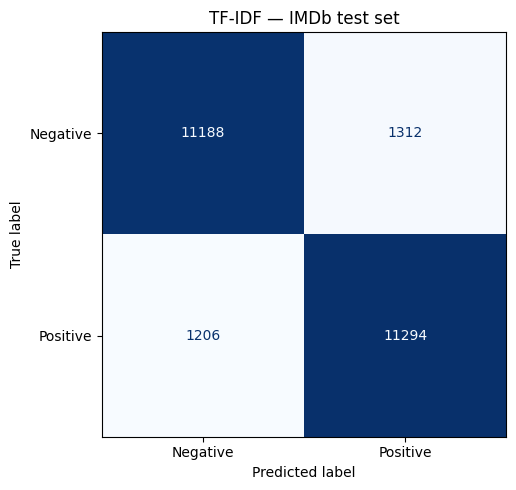

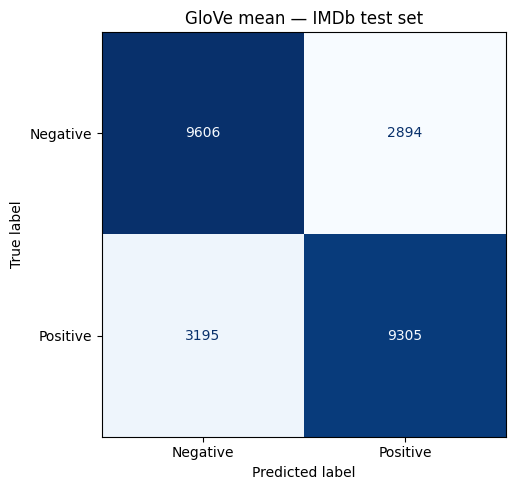

In [7]:
for label, pred, outfile in [
    ("TF-IDF", pred_tfidf, "confusion_matrix_tfidf.png"),
    ("GloVe mean", pred_glove, "confusion_matrix_glove.png")
]:
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Negative", "Positive"], ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{label} — IMDb test set")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / outfile, dpi=180)
    plt.show()

## 8. Predict unseen, custom-written reviews
These examples are separate from the held-out IMDb evaluation; they demonstrate how to use the trained classifiers.

In [8]:
reviews = [
    "I loved this movie. The performances were excellent and the story was moving.",
    "The script was dull, the acting was terrible and the film was a waste of time.",
    "It was not bad, but the ending was disappointing."
]
new_clean = [clean_text(t) for t in reviews]
new_tfidf = model_tfidf.predict(vectorizer.transform(new_clean))
new_glove = model_glove.predict(np.vstack([glove_review_vector(t) for t in new_clean]))
for review, a, b in zip(reviews, new_tfidf, new_glove):
    print("Review:", review)
    print("  TF-IDF:", "Positive" if a else "Negative", "| GloVe:", "Positive" if b else "Negative")

Review: I loved this movie. The performances were excellent and the story was moving.
  TF-IDF: Positive | GloVe: Positive
Review: The script was dull, the acting was terrible and the film was a waste of time.
  TF-IDF: Negative | GloVe: Negative
Review: It was not bad, but the ending was disappointing.
  TF-IDF: Negative | GloVe: Negative
